Predict future averge price of Meat, Fish and Eggs monthly in Yangon by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2021-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2021-07-01")
pred_end_date = pd.to_datetime("2022-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preperation for Prediction

In [12]:
DMFEM_Y = data.copy()
mask = (DMFEM_Y['category']=='meat, fish and eggs') & (DMFEM_Y['region']=='Yangon')
DMFEM_Y = DMFEM_Y.loc[mask]
DMFEM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
27760,7/15/2021,Yangon,Yangon (East),Zamyinzwel,"meat, fish and eggs",Eggs (local),local,NaN,10 pcs,actual,Retail,MMK,1800.00,1.0112
27766,7/15/2021,Yangon,Yangon (North),Meegwet,"meat, fish and eggs",Eggs (local),local,NaN,10 pcs,actual,Retail,MMK,1350.00,0.7584
27773,7/15/2021,Yangon,Yangon (North),YwarMa,"meat, fish and eggs",Eggs (local),local,NaN,10 pcs,actual,Retail,MMK,2000.00,1.1236
28898,9/15/2021,Yangon,Yangon (East),Ngazalgwae,"meat, fish and eggs",Eggs (local),local,NaN,10 pcs,actual,Retail,MMK,1250.00,0.7022
28905,9/15/2021,Yangon,Yangon (East),Zamyinzwel,"meat, fish and eggs",Eggs (local),local,NaN,10 pcs,actual,Retail,MMK,1166.67,0.6554


In [13]:
DMFEM_Y = DMFEM_Y[['date', 'price']]
DMFEM_Y['date'] = pd.to_datetime(DMFEM_Y['date'])
mask = (DMFEM_Y['date']>=obv_st_date) & (DMFEM_Y['date']<=obv_end_date)
DMFEM_Y = DMFEM_Y.loc[mask]
DMFEM_Y = DMFEM_Y.set_index('date')
DMFEM_Y.head()

,price
date,
2021-07-15,1800.00
2021-07-15,1350.00
2021-07-15,2000.00
2021-09-15,1250.00
2021-09-15,1166.67


In [14]:
DMFEM_Y = DMFEM_Y.resample('MS').mean()
DMFEM_Y.head()

,price
date,
2021-07-01,1716.666667
2021-08-01,NaN
2021-09-01,1254.167500
2021-10-01,1330.000000
2021-11-01,1293.334000


In [15]:
DMFEM_Y.tail()

,price
date,
2021-09-01,1254.1675
2021-10-01,1330.0000
2021-11-01,1293.3340
2021-12-01,1333.3340
2022-01-01,1283.4000


### According to this dataframe, we need to reset again datatime.

In [16]:
obv_st_date = pd.to_datetime("2021-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2021-07-01")
pred_end_date = pd.to_datetime("2022-09-01")

In [17]:
mask = (DMFEM_Y.index>=obv_st_date) & (DMFEM_Y.index<=obv_end_date)
DMFEM_Y = DMFEM_Y.loc[mask]
DMFEM_Y

,price
date,
2021-07-01,1716.666667
2021-08-01,NaN
2021-09-01,1254.167500
2021-10-01,1330.000000
2021-11-01,1293.334000
2021-12-01,1333.334000
2022-01-01,1283.400000


In [18]:
DMFEM_Y = DMFEM_Y.interpolate(method='linear')
DMFEM_Y.shape

(7, 1)

There are only 7 records. We have not enough record for prediction. However let test it.

In [19]:
price = DMFEM_Y['price']
date = DMFEM_Y.index

##### Normalization data

In [20]:
scaler = MinMaxScaler()

In [21]:
DMFEM_Y_nor = scaler.fit_transform(DMFEM_Y)
DMFEM_Y_nor = pd.DataFrame(DMFEM_Y_nor)
DMFEM_Y_nor.head()

,0
0,1.000000
1,0.500000
2,0.000000
3,0.163962
4,0.084684


In [22]:
DMFEM_Y_nor['date']=date
DMFEM_Y_nor = DMFEM_Y_nor.set_index('date')
DMFEM_Y_nor.columns=['price']
DMFEM_Y_nor.head()

,price
date,
2021-07-01,1.000000
2021-08-01,0.500000
2021-09-01,0.000000
2021-10-01,0.163962
2021-11-01,0.084684


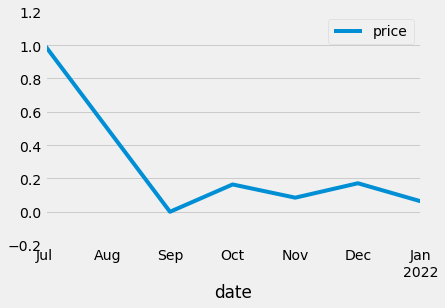

In [23]:
DMFEM_Y_nor.plot(grid=True)
plt.show()

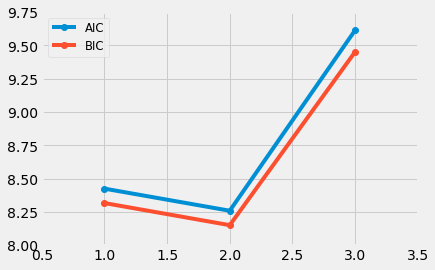

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DMFEM_Y_nor, p=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(1,0,0), 3:(1,0,1)

In [25]:
AIC, BIC

(array([10.1731215 ,  8.42506039,  8.25924679,  9.61248329]),
 array([10.11903165,  8.31688069,  8.15106709,  9.45021373]))

We will run again 1:(0,0,1), 2:(1,0,0)

In [26]:
mod_orders = [    
    (0,0,1),
    (1,0,0),
]

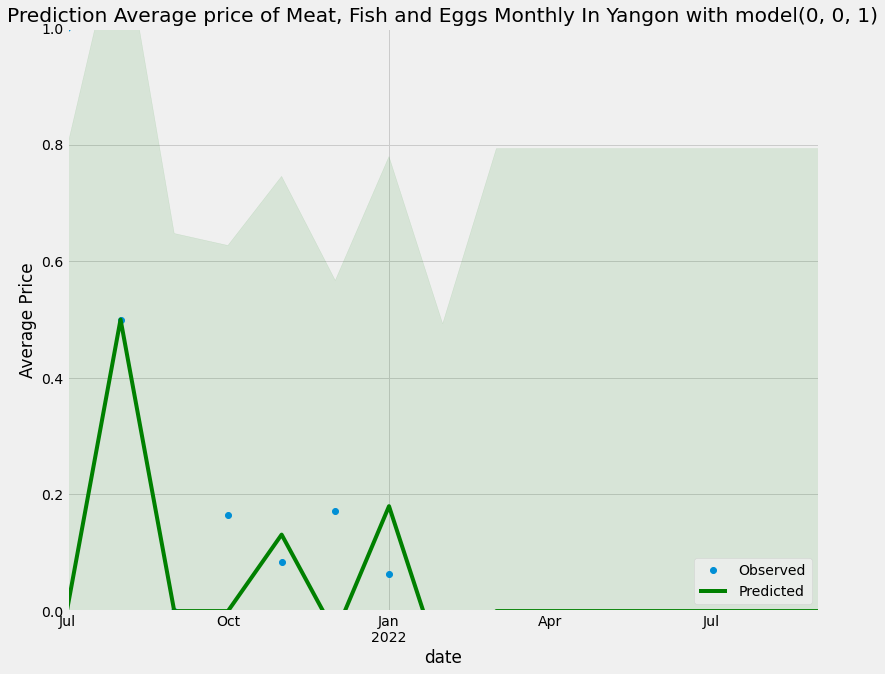

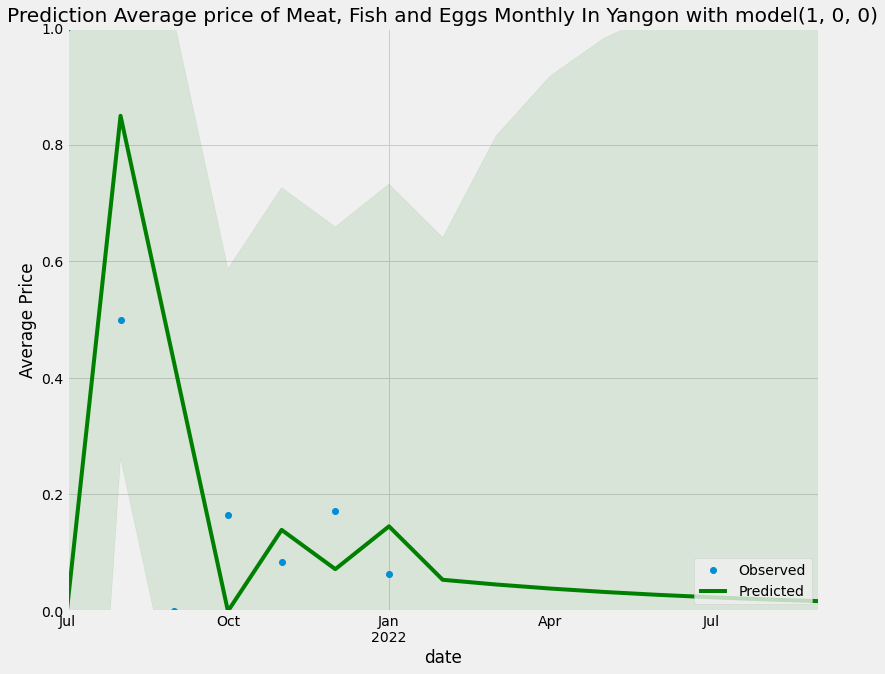

In [27]:
DMFEM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFEM_Y_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Meat, Fish and Eggs Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFEM_Y_models.append(model)

Now we choose (0,0,1)

In [28]:
DMFEM_Y_model = DMFEM_Y_models[0]

In [29]:
DMFEM_Y_pred_normalized = DMFEM_Y_model.predict(pred_st_date, pred_end_date)
DMFEM_Y_pred_normalized

2021-07-01    0.000000e+00
2021-08-01    5.000000e-01
2021-09-01    7.826928e-09
2021-10-01   -5.870196e-09
2021-11-01    1.311700e-01
2021-12-01   -3.873790e-02
2022-01-01    1.799220e-01
2022-02-01   -1.021269e-01
2022-03-01    0.000000e+00
2022-04-01    0.000000e+00
2022-05-01    0.000000e+00
2022-06-01    0.000000e+00
2022-07-01    0.000000e+00
2022-08-01    0.000000e+00
2022-09-01    0.000000e+00
Freq: MS, dtype: float64

In [30]:
mask = (DMFEM_Y_nor.index>=pred_st_date) & (DMFEM_Y_nor.index<=pred_end_date)
DMFEM_Y_pred = DMFEM_Y_nor.loc[mask]
DMFEM_Y_pred

,price
date,
2021-07-01,1.000000
2021-08-01,0.500000
2021-09-01,0.000000
2021-10-01,0.163962
2021-11-01,0.084684
2021-12-01,0.171171
2022-01-01,0.063206


We need to un-normalized the predicted value to get actual price

In [31]:
pred_date = DMFEM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2021-07-01', '2021-08-01', '2021-09-01', '2021-10-01',
               '2021-11-01', '2021-12-01', '2022-01-01', '2022-02-01',
               '2022-03-01', '2022-04-01', '2022-05-01', '2022-06-01',
               '2022-07-01', '2022-08-01'],
              dtype='datetime64[ns]', freq='MS')

In [32]:
DMFEM_Y_pred_normalized_df = pd.DataFrame(DMFEM_Y_pred_normalized)
DMFEM_Y_pred_normalized_df = DMFEM_Y_pred_normalized_df[:-1] # the last index doesn't need
DMFEM_Y_pred_normalized_df

,0
2021-07-01,0.000000e+00
2021-08-01,5.000000e-01
2021-09-01,7.826928e-09
2021-10-01,-5.870196e-09
2021-11-01,1.311700e-01
2021-12-01,-3.873790e-02
2022-01-01,1.799220e-01
2022-02-01,-1.021269e-01
2022-03-01,0.000000e+00
2022-04-01,0.000000e+00


##### Un-normalization data

In [33]:
DMFEM_Y_pred_act = scaler.inverse_transform(DMFEM_Y_pred_normalized_df)
DMFEM_Y_pred_act_df = pd.DataFrame(DMFEM_Y_pred_act)
DMFEM_Y_pred_act_df['date'] = pred_date
DMFEM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DMFEM_Y_pred_act_df.set_index('date',  inplace=True)
DMFEM_Y_pred_act_df

,Predicted Price
date,
2021-07-01,1254.167500
2021-08-01,1485.417078
2021-09-01,1254.167504
2021-10-01,1254.167497
2021-11-01,1314.833498
2021-12-01,1236.251253
2022-01-01,1337.381274
2022-02-01,1206.933890
2022-03-01,1254.167500


In [34]:
mask = (DMFEM_Y.index>=pred_st_date) & (DMFEM_Y.index<=pred_end_date)
DMFEM_Y_Act = DMFEM_Y.loc[mask]
DMFEM_Y_Act

,price
date,
2021-07-01,1716.666667
2021-08-01,1485.417083
2021-09-01,1254.167500
2021-10-01,1330.000000
2021-11-01,1293.334000
2021-12-01,1333.334000
2022-01-01,1283.400000


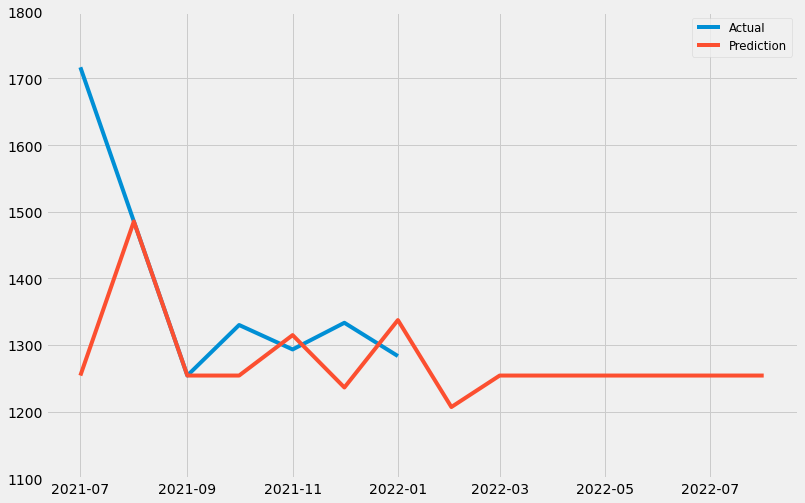

In [35]:
plt.figure(figsize=(12,8))
plt.plot(DMFEM_Y_Act, label="Actual")
plt.plot(DMFEM_Y_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [36]:
temp_df = DMFEM_Y_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2021-07-01,1.000000
1,2021-08-01,0.500000
2,2021-09-01,0.000000
3,2021-10-01,0.163962
4,2021-11-01,0.084684
5,2021-12-01,0.171171
6,2022-01-01,0.063206


In [37]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.65
train = temp_df[mask]
test = temp_df[~mask]
train, test

(        date     price                 time
 0 2021-07-01  1.000000  1625097600000000000
 1 2021-08-01  0.500000  1627776000000000000
 2 2021-09-01  0.000000  1630454400000000000
 3 2021-10-01  0.163962  1633046400000000000
 4 2021-11-01  0.084684  1635724800000000000
 6 2022-01-01  0.063206  1640995200000000000,
         date     price                 time
 5 2021-12-01  0.171171  1638316800000000000)

In [38]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1625097600000000000],
        [1627776000000000000],
        [1630454400000000000],
        [1633046400000000000],
        [1635724800000000000],
        [1640995200000000000]], dtype=int64),
 array([1.        , 0.5       , 0.        , 0.16396246, 0.08468448,
        0.06320552]))

In [39]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1638316800000000000]], dtype=int64), array([0.17117112]))

In [40]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [41]:
DMFEM_Y_linreg = LinearRegression().fit(X_train, y_train)

In [42]:
print('linear model coeff or slope (w): {}'.format(DMFEM_Y_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DMFEM_Y_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DMFEM_Y_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DMFEM_Y_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [-5.0681528e-17]
linear model intercept (b): 83.023
R-squared score (training): 0.567
R-squared score (test): nan


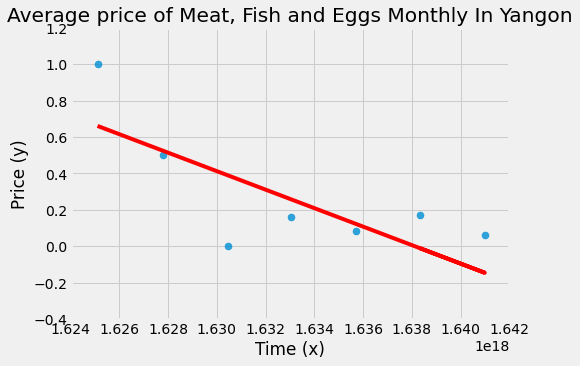

In [43]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DMFEM_Y_linreg.coef_ * X + DMFEM_Y_linreg.intercept_, 'r-')
plt.title('Average price of Meat, Fish and Eggs Monthly In Yangon')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [44]:
DMFEM_Y_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DMFEM_Y_linear_predict['time'] = DMFEM_Y_linear_predict['date'].apply(lambda x: x.value)
DMFEM_Y_linear_predict

,date,time
0,2021-07-01,1625097600000000000
1,2021-08-01,1627776000000000000
2,2021-09-01,1630454400000000000
3,2021-10-01,1633046400000000000
4,2021-11-01,1635724800000000000
5,2021-12-01,1638316800000000000
6,2022-01-01,1640995200000000000
7,2022-02-01,1643673600000000000
8,2022-03-01,1646092800000000000
9,2022-04-01,1648771200000000000


In [45]:
time_predict = np.array(DMFEM_Y_linear_predict['time']).reshape((-1, 1))
DMFEM_Y_linear_predict['price'] = DMFEM_Y_linreg.predict(time_predict)
DMFEM_Y_linear_predict

,date,time,price
0,2021-07-01,1625097600000000000,0.661044
1,2021-08-01,1627776000000000000,0.525298
2,2021-09-01,1630454400000000000,0.389553
3,2021-10-01,1633046400000000000,0.258187
4,2021-11-01,1635724800000000000,0.122441
5,2021-12-01,1638316800000000000,-0.008925
6,2022-01-01,1640995200000000000,-0.144671
7,2022-02-01,1643673600000000000,-0.280416
8,2022-03-01,1646092800000000000,-0.403025
9,2022-04-01,1648771200000000000,-0.538770


In [46]:
DMFEM_Y_linear_normalized_predict = DMFEM_Y_linear_predict.copy()
DMFEM_Y_linear_normalized_predict = DMFEM_Y_linear_normalized_predict[['date', 'price']]
DMFEM_Y_linear_normalized_predict.set_index('date', inplace=True)
DMFEM_Y_linear_normalized_predict

,price
date,
2021-07-01,0.661044
2021-08-01,0.525298
2021-09-01,0.389553
2021-10-01,0.258187
2021-11-01,0.122441
2021-12-01,-0.008925
2022-01-01,-0.144671
2022-02-01,-0.280416
2022-03-01,-0.403025


##### Unnormalized the data

In [47]:
DMFEM_Y_pred_act_linear = scaler.inverse_transform(DMFEM_Y_linear_normalized_predict)
DMFEM_Y_pred_act_linear_df = pd.DataFrame(DMFEM_Y_pred_act_linear)
DMFEM_Y_pred_act_linear_df['date'] = DMFEM_Y_linear_predict['date']
DMFEM_Y_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DMFEM_Y_pred_act_linear_df.set_index('date', inplace=True)
DMFEM_Y_pred_act_linear_df

,Predicted Price (KG)
date,
2021-07-01,1559.899752
2021-08-01,1497.117616
2021-09-01,1434.335479
2021-10-01,1373.578573
2021-11-01,1310.796436
2021-12-01,1250.039530
2022-01-01,1187.257394
2022-02-01,1124.475257
2022-03-01,1067.768811
